<a name='T'>

<p style="padding: 20px;
          background-color: black;
          font-family: computermodern;
          color: white;
          font-size: 200%;
          text-align: center;
          border-radius: 40px 20px;
          ">Assisted Coding Challenge #1 🩵 Backrooms Hill<br>
          </p>
<p style="font-family: computermodern;
          color: #000000;
          font-size: 175%;
          text-align: center;
          ">Programming Puzzle, "Specialist" Difficulty (1400 Elo)
             </p>

Welcome to my **Assisted Coding series**! Tougher problems, with a small AI assistant by your side: it can explain, give hints and review your code, but the solving is up to you.

Today, I propose an intermediate problem: the [Backrooms Hill](https://codeforces.com/problemset/problem/2267/D) puzzle from CodeForces. Let's dive into it!

<a id="TOC"></a>

<div style="background-color: #e0f2f1; border-left: 10px solid #009688; padding: 20px; margin-bottom: 20px; border-radius: 8px; box-shadow: 0 2px 5px rgba(0,0,0,0.1);">
    <h3 style="color: #00796b;">Table of Contents</h3>
    <ul style="list-style-type: none;">
        <li><a href="#s1" style="color: #00695c;"><strong>1. Instructions</strong></a></li>
        <li><a href="#s2" style="color: #00695c;"><strong>2. Input and Output</strong></a></li>
        <li><a href="#s3a" style="color: #00695c;"><strong>3. Your AI Teammate</strong></a></li>
        <li><a href="#s3" style="color: #00695c;"><strong>4. Show Time!</strong></a></li>
        <li><a href="#s4" style="color: #00695c;"><strong>5. Evaluation</strong></a></li>
        <li><a href="#s5" style="color: #00695c;"><strong>6. Proposed Solution</strong></a></li>
    </ul>
</div>

*Notebook by Ir. Alexandre Le Mercier.*

In [1]:
import sys
import importlib
import subprocess
from pathlib import Path

# A copy cloned by an earlier run (Kaggle keeps it for the whole session): bring it up to date.
clone_path = Path.cwd() / 'assisted-coding-challenges'
if (clone_path / '.git').is_dir():
    if subprocess.run(['git', '-C', str(clone_path), 'pull', '-q', '--ff-only']).returncode:
        print('Could not update the repository: using the copy cloned earlier.')

# Reuse a local checkout, including when running from a nearby notebook folder.
required_files = ('utils.py', 'assistant.py', 'acc1_utils.py', 'acc1_tests.txt')
repo_path = next((
    candidate
    for parent in (Path.cwd(), *Path.cwd().parents)
    for candidate in (parent, parent / 'assisted-coding-challenges', parent / 'Assisted Coding Challenges')
    if all((candidate / name).is_file() for name in required_files)
), None)

# Kaggle (or a standalone local notebook): clone when no checkout is available.
if repo_path is None:
    repo_path = clone_path
    subprocess.run(['git', 'clone', 'https://github.com/TortueSagace/assisted-coding-challenges.git', str(repo_path), '-q'], check=True)

repo_path = str(repo_path.resolve())
if repo_path not in sys.path:
    sys.path.insert(0, repo_path)

# Reload when this cell runs again in the same kernel, so updated files are used.
import utils, acc1_utils
importlib.reload(utils)
importlib.reload(acc1_utils)
from utils import *
from acc1_utils import *

C:\Users\Administrator\OneDrive - UGent\PhD\PhD Related Python Codes\chess-maml\chess-hispa\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<a id="s1"></a>
<div style="color: black; background-color: #E6E6FA; padding: 10px; border-left: 5px solid purple; border-radius: 5px;">  
    <h1>1. Instructions</h1>
</div>

[Back to table of contents](#TOC)

***This one is meant to be solved as a team: you and a small AI assistant (see [section 3](#s3a)). Neither of you is expected to crack it alone!*** 🤝

Among the people from the city *GR*, there is a legend about a hill that leads to the backstage. An array $b$ consisting of $m$ integers is called a *hill* if there exists an index $k$ ($1\le k\le m$) such that the following conditions hold:

- The first $k$ elements are strictly increasing. Formally, for all $i$ ($1\le i\lt k$), $b_i\lt b_{i+1}$.
- The last $m-k+1$ elements are strictly decreasing. Formally, for all $i$ ($k\le i\lt m$), $b_i\gt b_{i+1}$.

You are given an array $a$ consisting of $n$ **distinct** integers. You may perform the following operation any number of times:

- Choose any index $i$ ($1\le i\le n-2$).
- Swap $a_i$ and $a_{i+2}$ in the array.

Your task is to determine whether it is possible to turn array $a$ into a *hill* by performing the operation any number of times.

<a id="s2"></a>
<div style="color: black; background-color: #E6E6FA; padding: 10px; border-left: 5px solid purple; border-radius: 5px;">  
    <h1>2. Input and Output</h1>
</div>

[Back to table of contents](#TOC)

## Input

Your function receives:
- `n` (int): the length of the array (`1 ≤ n ≤ 10^5`)
- `a` (list of int): the array, a permutation of `1..n` (distinct values with `1 ≤ a_i ≤ n`)

## Output

Your function must return a str `answer`: "YES" if the array can be turned into a hill, "NO" otherwise.

## Sample Test Cases

| n | a | Expected Output | Explanation |
|---|---|-----------------|-------------|
| 3 | `[2, 1, 3]` | `'NO'` | The smallest value 1 must end at position 1 or 3, but it sits on an even position and can only move between even positions → NO. |
| 4 | `[1, 2, 3, 4]` | `'YES'` | The array is already a hill → YES. |
| 6 | `[5, 3, 4, 6, 2, 1]` | `'YES'` | Swapping a₁ ↔ a₃ then a₂ ↔ a₄ gives the hill [4, 6, 5, 3, 2, 1] (see the Note) → YES. |
| 6 | `[1, 5, 2, 3, 6, 4]` | `'NO'` | 1 must go to an end: position 1 (odd, like 1). Then 2 must go to position 2 or 6, both even, but 2 is on an odd position → NO. |
| 7 | `[1, 2, 3, 4, 7, 5, 6]` | `'NO'` | In a hill, 6 must sit right next to the peak 7, but both are on odd positions and can never become neighbours → NO. |
| 5 | `[5, 4, 1, 3, 2]` | `'YES'` | Swapping a₁ ↔ a₃ gives the hill [1, 4, 5, 3, 2] → YES. |
| 6 | `[4, 1, 3, 2, 6, 5]` | `'NO'` | 1 is on an even position, so it must go to position 6. Then 2 (also even) must go to position 1 or 5, both odd → NO. |

<a id="s3a"></a>
<div style="color: black; background-color: #E6E6FA; padding: 10px; border-left: 5px solid purple; border-radius: 5px;">  
    <h1>3. Your AI Teammate</h1>
</div>

[Back to table of contents](#TOC)

This problem is harder than usual, and meant to be solved **as a team**: you and a small AI model that has read the statement. It is fast but doesn't reason, so it won't crack the problem alone. You bring the ideas and the judgment; it explains, checks and debugs.

**Setup (once)**
- Get a free key at [openrouter.ai/keys](https://openrouter.ai/keys).
- Save it in **one** of these two ways, depending on where you run the notebook:
    - **On Kaggle:** *Add-ons → Secrets* → add `OPENROUTER_API_KEY` → tick it for this notebook.
    - **On your computer:** put `OPENROUTER_API_KEY=...` in a `.env` file next to the notebook.
- Run the setup cell below.

**Use**
- `ask("...")`: write your question in the cell below the setup (or in any cell). Once your solution cell has run, it and its sample results are sent too.
- `fix()` as the **last line of your solution cell** (section 4), then run that cell: the cell is replaced by a corrected version.
- `undo()`, same place: brings your version back.
- `reset()`: starts a new conversation.

**Good to know**
- It only sees the statement, the samples and your solution cell as you last ran it: rerun that cell before asking.
- Free OpenRouter accounts have a daily cap on free requests; the assistant tells you when you reach it.
- Free models may log prompts: don't paste anything private.

In [ ]:
######################### AI ASSISTANT ###########################
# Run this cell once: nothing to change here.

import assistant
importlib.reload(assistant)
from assistant import ask, fix, undo, reset

assistant.start(Path(repo_path) / 'acc1_context.md')

In [ ]:
######################### YOUR QUESTIONS ###########################
# Write your question between the quotes, then run this cell. Ask as often as you like.
# For example: ask("Could a greedy approach work here?")

ask("")

<a id="s3"></a>
<div style="color: black; background-color: #E6E6FA; padding: 10px; border-left: 5px solid purple; border-radius: 5px;">  
    <h1>4. Show Time!</h1>
</div>

[Back to table of contents](#TOC)

***Time to team up! Work out the approach with your assistant, then implement it below.*** 🧠🤝

Implement your solution in the `my_solution(n, a)` function below. The function should return `answer` as described above.

**Time limit per test**: 2 seconds.

**Memory limit per test**: 256 megabytes.

In [4]:
######################### SETUP ############################

samples = [
    [3, [2, 1, 3]],
    [4, [1, 2, 3, 4]],
    [6, [5, 3, 4, 6, 2, 1]],
    [6, [1, 5, 2, 3, 6, 4]],
    [7, [1, 2, 3, 4, 7, 5, 6]],
    [5, [5, 4, 1, 3, 2]],
    [6, [4, 1, 3, 2, 6, 5]]
]

TIME_LIMIT = 2
MEMORY_LIMIT = 256e6

print(f"Loaded {len(samples)} sample test cases.")

Loaded 7 sample test cases.


In [5]:
######################### RESOLUTION ###########################

def my_solution(n, a):
    """
    Decide whether swapping elements two positions apart can turn the array into a hill.
    
    Parameters:
    -----------
    n : int
        The length of the array (1 ≤ n ≤ 10^5)
    a : list of int
        The array, a permutation of 1..n (distinct values with 1 ≤ a_i ≤ n)
    
    Returns:
    --------
    str : "YES" if the array can be turned into a hill, "NO" otherwise
    """
    
    # --> Your solution here! <--
    
    pass  # Remove this and return answer

# To let your assistant correct this cell, uncomment the next line and run the cell.
# fix()

ℹ️ **Tips**
- Run the cell below to test your solution on the sample test cases.
- Each test case has exactly one correct answer.

In [6]:
##################### ACCURACY AND EFFICIENCY CHECK ########################

evaluate_on_samples(samples, my_solution, check_solution, TIME_LIMIT, MEMORY_LIMIT)


                         Sample Test Results                          
   # │ Input                      │ Output │         Time │ Status    
─────┼────────────────────────────┼────────┼──────────────┼───────────
   1 │ [3, [2, 1, 3]]             │ None   │      57.8 μs │ ❌ Wrong   
   2 │ [4, [1, 2, 3, 4]]          │ None   │      15.7 μs │ ❌ Wrong   
   3 │ [6, [5, 3, 4, 6, 2, 1]]    │ None   │      12.2 μs │ ❌ Wrong   
   4 │ [6, [1, 5, 2, 3, 6, 4]]    │ None   │      12.3 μs │ ❌ Wrong   
   5 │ [7, [1, 2, 3, 4, 7, 5, 6]] │ None   │      12.9 μs │ ❌ Wrong   
   6 │ [5, [5, 4, 1, 3, 2]]       │ None   │      13.0 μs │ ❌ Wrong   
   7 │ [6, [4, 1, 3, 2, 6, 5]]    │ None   │      10.5 μs │ ❌ Wrong   

❌  0/7 sample tests passed
    First failure: Invalid output: function returned None. Did you run the cell containing your solution?


<a id="s4"></a>
<div style="color: black; background-color: #E6E6FA; padding: 10px; border-left: 5px solid purple; border-radius: 5px;">  
    <h1>5. Evaluation</h1>
</div>

[Back to table of contents](#TOC)

Run the cell below to evaluate your solution on 300 hidden test cases. You are supposed to be already confident about your solution before doing this. Please note that in competitive programming, submitting several wrong answers to the tester results in time penalties. However, feel free to run the cell above with `evaluate_on_samples` as many times as you like!

In [7]:
##################### INTERNAL EVALUATION ########################

test_file_path = str(Path(repo_path) / 'acc1_tests.txt')

if internal_evaluation(test_file_path, my_solution, check_solution, parse_tests, TIME_LIMIT, MEMORY_LIMIT, get_input_size=get_input_size, plot_title='Backrooms Hill', show_estimation=True):
    print("✅ The proposed solution meets both accuracy and efficiency requirements")

  0%|          | 0/300 [00:00<?, ?it/s]

❌ 100.0% wrong: 100%|██████████| 300/300 [00:00<00:00, 49991.70it/s]

❌ 100.0% wrong: 100%|██████████| 300/300 [00:00<00:00, 42838.36it/s]


❌  300/300 hidden tests failed (100.0%)
    First failure (test 1): Invalid output: function returned None. Did you run the cell containing your solution?


<a id="s5"></a>
<div style="color: black; background-color: #E6E6FA; padding: 10px; border-left: 5px solid purple; border-radius: 5px;">  
    <h1>6. Proposed Solution</h1>
</div>

[Back to table of contents](#TOC)

Here is a correct solution. It doesn't necessarily mean that it is the *only* correct one.

<details>
<summary><strong>💡 Click to reveal Solution Explanation</strong></summary>

<div style="color: black; background-color: #cce5ff; padding: 10px; border-left: 5px solid #3399ff; border-radius: 5px; margin-top: 10px;">
    <strong>Key insight:</strong> swapping aᵢ and aᵢ₊₂ never changes the parity of a value's position, and it can rearrange the odd positions in any order, and the even positions in any order. So the only question is whether some hill puts every value on a position of its own parity.<br><br>
    <strong>Strategy:</strong>
    <ol>
        <li>Record, for each value, the parity of its position in a.</li>
        <li>Build the hill from the bottom: in a hill, the smallest value is at one end, and once it is removed, what remains is still a hill. So the values 1, 2, …, n−1 are placed in increasing order, each at the leftmost or the rightmost free position, and n ends up as the peak.</li>
        <li>If i values went to the left so far, value v goes to position i+1 (left) or n−(v−1−i) (right). Both parities depend only on the parity of i, so we keep the set of reachable parities of i (at most two) and update it for each value, keeping only the placements whose position parity matches the value's.</li>
        <li>At the end, the peak n sits at position i+1: the answer is YES if that parity matches n's for some reachable i.</li>
    </ol>
    <strong>Why it works:</strong> every hill arises from exactly such a sequence of left/right choices, and a hill is reachable by the swaps exactly when every value lands on a position of its own parity. The positions only matter through their parity, so tracking the parity of i loses nothing. The whole check is O(n).
</div>

</details><br>

Both time and space complexities of this solution are $\mathcal O(n)$.

In [8]:
######################### PROPOSED SOLUTION ###########################

def proposed_solution(n, a):
    # Swapping a_i and a_{i+2} rearranges the odd positions freely, and the even positions freely:
    # each value keeps only the parity of its position.
    parity = [0] * (n + 1)
    for pos, value in enumerate(a, start=1):
        parity[value] = pos % 2

    # In a hill, n is the peak; going through the values 1, 2, ..., n-1 in increasing order, each one
    # takes the next free position from the left end or from the right end.
    # With i values already on the left (and v-1-i on the right), value v goes to position i+1 or n-(v-1-i).
    # Only the parity of i matters for those positions, so we track which parities of i are reachable.
    reachable = {0}
    for v in range(1, n):
        nxt = set()
        for p in reachable:
            if (p + 1) % 2 == parity[v]:           # left: position i+1, i grows by one
                nxt.add((p + 1) % 2)
            if (n - v + 1 + p) % 2 == parity[v]:   # right: position n-(v-1-i), i unchanged
                nxt.add(p)
        reachable = nxt
        if not reachable:
            return "NO"

    # The peak n ends at position i+1.
    return "YES" if any((p + 1) % 2 == parity[n] for p in reachable) else "NO"


Testing proposed solution on hidden tests:


  0%|          | 0/300 [00:00<?, ?it/s]

  4%|▍         | 12/300 [00:00<00:03, 93.70it/s]

 16%|█▌        | 47/300 [00:00<00:01, 216.21it/s]

 26%|██▌       | 77/300 [00:00<00:00, 250.93it/s]

...

 59%|█████▊    | 176/300 [00:00<00:00, 301.94it/s]

 69%|██████▉   | 208/300 [00:00<00:00, 299.05it/s]

 91%|█████████ | 272/300 [00:00<00:00, 341.85it/s]

100%|██████████| 300/300 [00:00<00:00, 303.43it/s]

✅  All 300 tests passed!


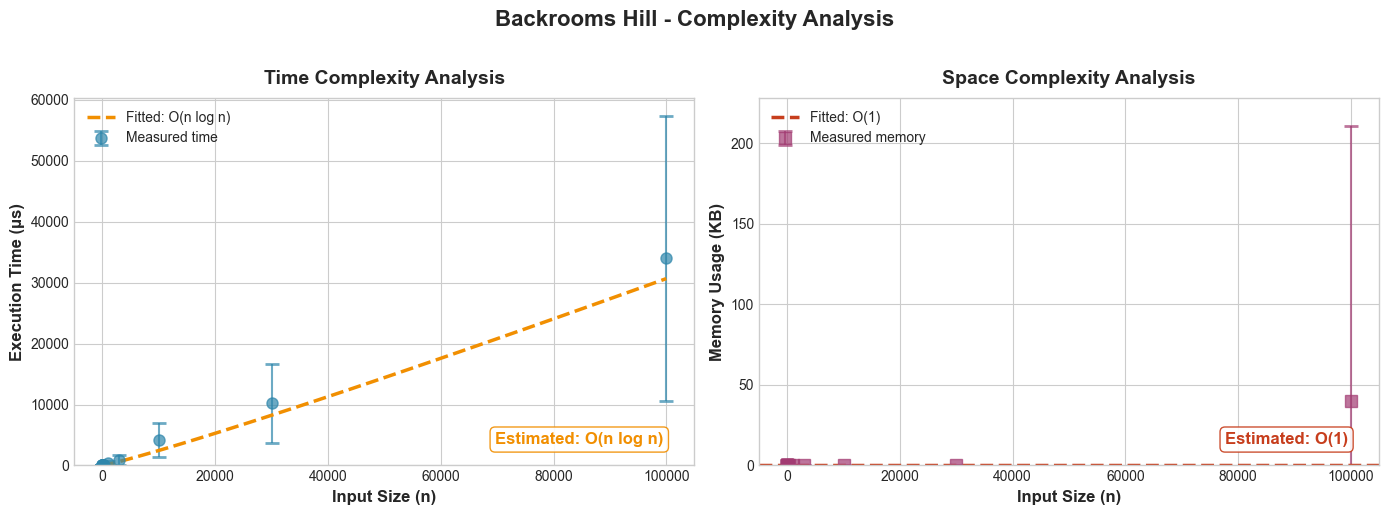


📊 Estimated Time Complexity: O(n log n)
📊 Estimated Space Complexity: O(1)
✅ The proposed solution meets both accuracy and efficiency requirements


In [9]:
##################### VERIFY PROPOSED SOLUTION ########################

print("\nTesting proposed solution on hidden tests:")
if internal_evaluation(test_file_path, proposed_solution, check_solution, parse_tests, TIME_LIMIT, MEMORY_LIMIT, get_input_size=get_input_size, plot_title='Backrooms Hill', show_estimation=True):
    print("✅ The proposed solution meets both accuracy and efficiency requirements")

<p style="padding: 20px;
          background-color: green;
          font-family: computermodern;
          color: white;
          font-size: 200%;
          text-align: center;
          border-radius: 40px 20px;
          ">Thank you! If you found this useful, please upvote 👍</p>